<a href="https://colab.research.google.com/github/vaanchhitbaranwal-ux/Vaanchhit/blob/main/Job_Market_EDA_DataAnalyst.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Exploratory Data Analysis (EDA) - Data Analyst Job Market
This notebook demonstrates standard EDA on a Job Market dataset. It covers:
1. Data Simulation / Loading
2. Basic Dataset Statistics
3. Job Distribution Analysis (Roles, Locations)
4. Salary Distribution Analysis
5. Skills Demand Analysis

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from collections import Counter

# Set plotting style
sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (12, 6)

# 1. Simulate a Job Market Dataset
np.random.seed(42)
n_samples = 500

jobs = ['Data Analyst', 'Senior Data Analyst', 'Data Scientist', 'BI Analyst', 'Data Engineer']
companies = ['TechCorp', 'FinanceHub', 'HealthData', 'RetailGiant', 'EduLearn', 'InnoSoft']
locations = ['New York, NY', 'San Francisco, CA', 'Chicago, IL', 'Austin, TX', 'Remote', 'Boston, MA']
skills_pool = ['Python', 'SQL', 'R', 'Tableau', 'PowerBI', 'Excel', 'Spark', 'AWS', 'Machine Learning']

data = {
    'Job_Title': np.random.choice(jobs, n_samples, p=[0.4, 0.2, 0.15, 0.15, 0.1]),
    'Company': np.random.choice(companies, n_samples),
    'Location': np.random.choice(locations, n_samples, p=[0.2, 0.2, 0.15, 0.15, 0.2, 0.1]),
    'Min_Salary': np.random.randint(50000, 110000, n_samples),
    'Max_Salary': np.random.randint(80000, 180000, n_samples),
    'Rating': np.round(np.random.uniform(3.0, 5.0, n_samples), 1),
    'Job_Description': [
        ", ".join(np.random.choice(skills_pool, np.random.randint(2, 6), replace=False))
        for _ in range(n_samples)
    ]
}

df = pd.DataFrame(data)
# Ensure Max Salary is always greater than or equal to Min Salary
df['Max_Salary'] = df.apply(lambda row: max(row['Min_Salary'] + 10000, row['Max_Salary']), axis=1)
df['Average_Salary'] = (df['Min_Salary'] + df['Max_Salary']) / 2

display(df.head())

,Job_Title,Company,Location,Min_Salary,Max_Salary,Rating,Job_Description,Average_Salary
0,Data Analyst,InnoSoft,"Chicago, IL",52356,152240,4.2,"Machine Learning, AWS, R, Excel, PowerBI",102298.0
1,Data Engineer,TechCorp,"Boston, MA",54790,144315,4.1,"SQL, R, Spark",99552.5
2,Data Scientist,TechCorp,"Austin, TX",76911,149249,4.1,"Machine Learning, Python",113080.0
3,Senior Data Analyst,TechCorp,"New York, NY",99458,150587,4.2,"Excel, Spark, Tableau",125022.5
4,Data Analyst,EduLearn,"Boston, MA",74363,90756,4.4,"Excel, SQL, Machine Learning, Python",82559.5


## Basic Dataset Statistics

In [ ]:
print("--- Dataset Info ---")
print(df.info())
print("\n--- Missing Values ---")
print(df.isnull().sum())
print("\n--- Descriptive Statistics ---")
display(df.describe())

--- Dataset Info ---
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 500 entries, 0 to 499
Data columns (total 8 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   Job_Title        500 non-null    object 
 1   Company          500 non-null    object 
 2   Location         500 non-null    object 
 3   Min_Salary       500 non-null    int64  
 4   Max_Salary       500 non-null    int64  
 5   Rating           500 non-null    float64
 6   Job_Description  500 non-null    object 
 7   Average_Salary   500 non-null    float64
dtypes: float64(2), int64(2), object(4)
memory usage: 31.4+ KB
None

--- Missing Values ---
Job_Title          0
Company            0
Location           0
Min_Salary         0
Max_Salary         0
Rating             0
Job_Description    0
Average_Salary     0
dtype: int64

--- Descriptive Statistics ---


,Min_Salary,Max_Salary,Rating,Average_Salary
count,500.000000,500.000000,500.000000,500.000000
mean,80207.840000,132872.410000,3.985400,106540.125000
std,16642.076778,26623.539579,0.573572,15844.438281
min,50125.000000,80207.000000,3.000000,65581.500000
25%,66010.750000,109977.000000,3.500000,95460.625000
50%,81063.000000,131297.500000,4.000000,106277.250000
75%,93877.250000,153991.000000,4.500000,118221.375000
max,109975.000000,179983.000000,5.000000,144247.000000


## Visualizations

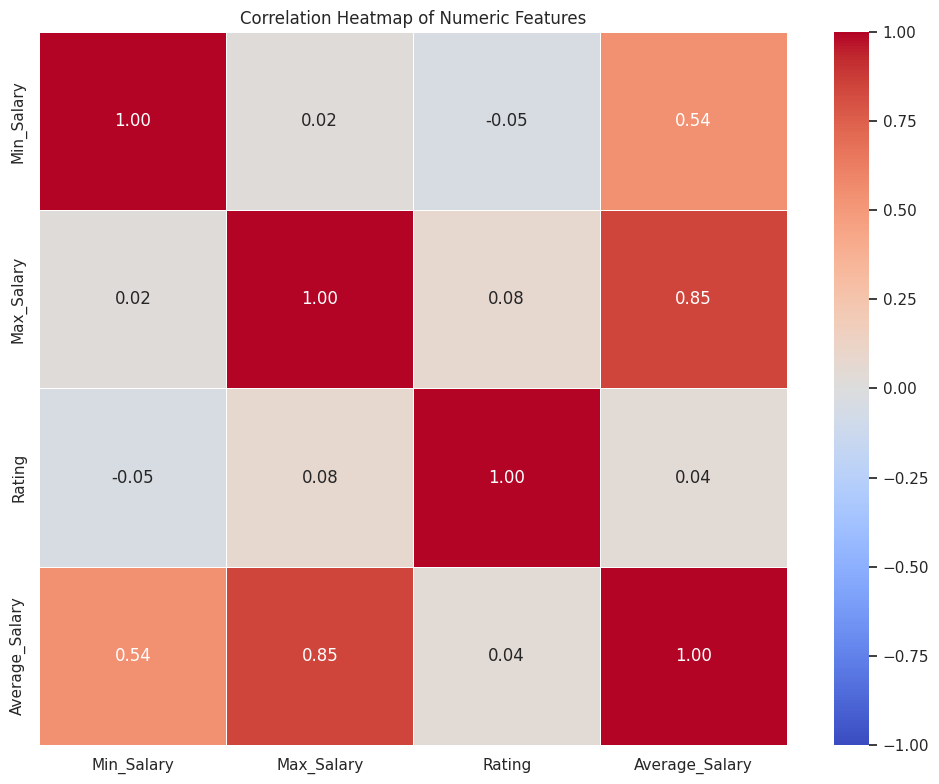

In [ ]:
# Select all numeric columns in the DataFrame
numeric_df = df.select_dtypes(include=[np.number])

# Calculate the Pearson correlation matrix
correlation_matrix = numeric_df.corr()

# Generate the heatmap visualization
plt.figure(figsize=(10, 8))
sns.heatmap(
    correlation_matrix,
    annot=True,
    cmap='coolwarm',
    fmt='.2f',
    linewidths=0.5,
    vmin=-1,
    vmax=1
)

plt.title('Correlation Heatmap of Numeric Features')
plt.tight_layout()
plt.show()

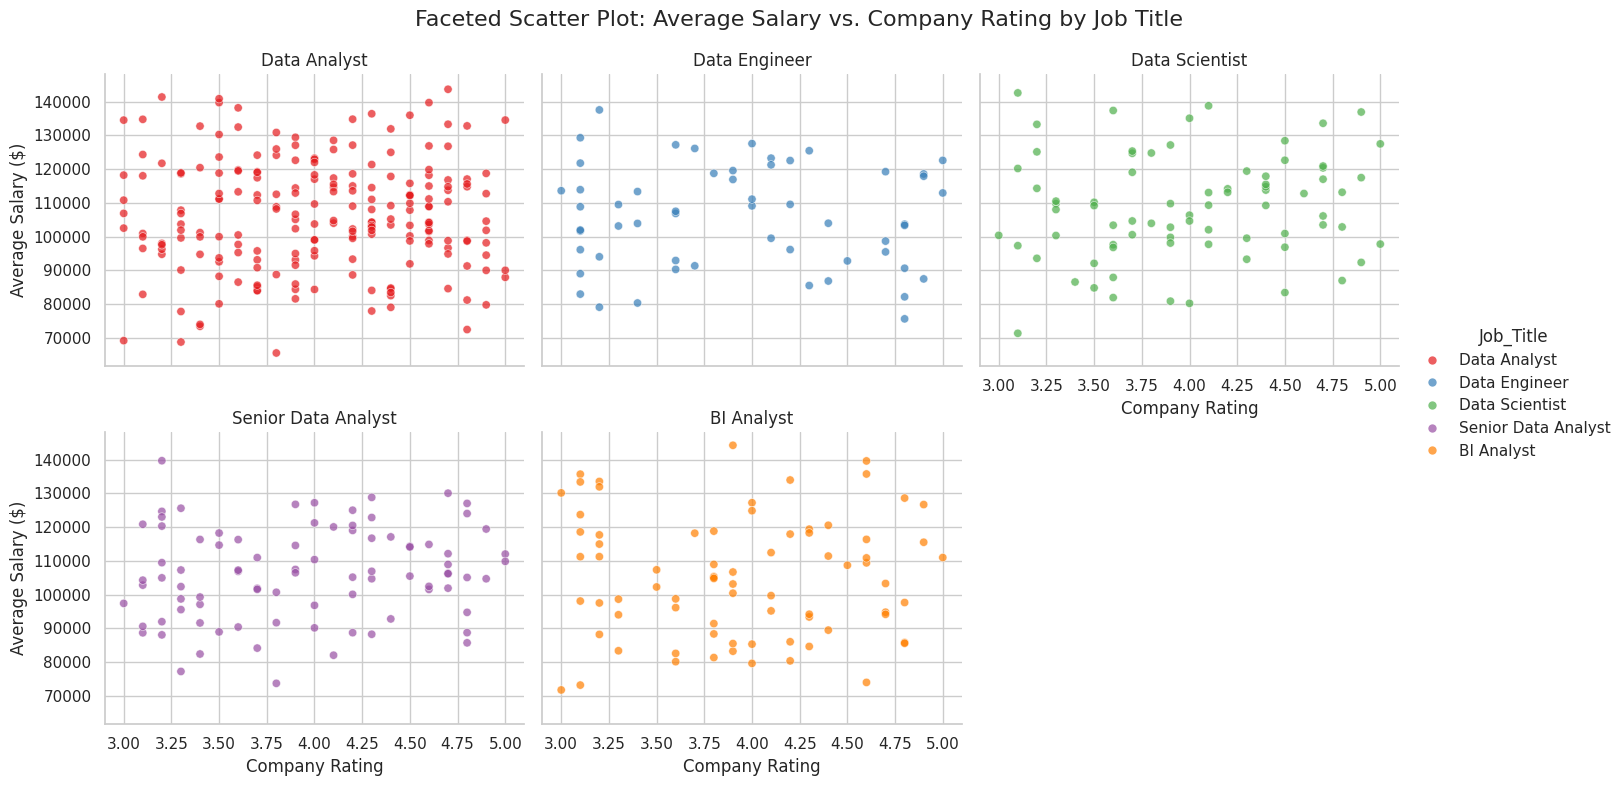

In [ ]:
# Create a faceted scatter plot using Seaborn's relplot
g = sns.relplot(
    data=df,
    x='Rating',
    y='Average_Salary',
    col='Job_Title',
    col_wrap=3,
    hue='Job_Title',
    palette='Set1',
    kind='scatter',
    alpha=0.7,
    height=4,
    aspect=1.2
)

# Adjust titles and labels
g.set_titles("{col_name}")
g.set_axis_labels("Company Rating", "Average Salary ($)")
plt.subplots_adjust(top=0.9)
g.fig.suptitle('Faceted Scatter Plot: Average Salary vs. Company Rating by Job Title', fontsize=16)
plt.show()

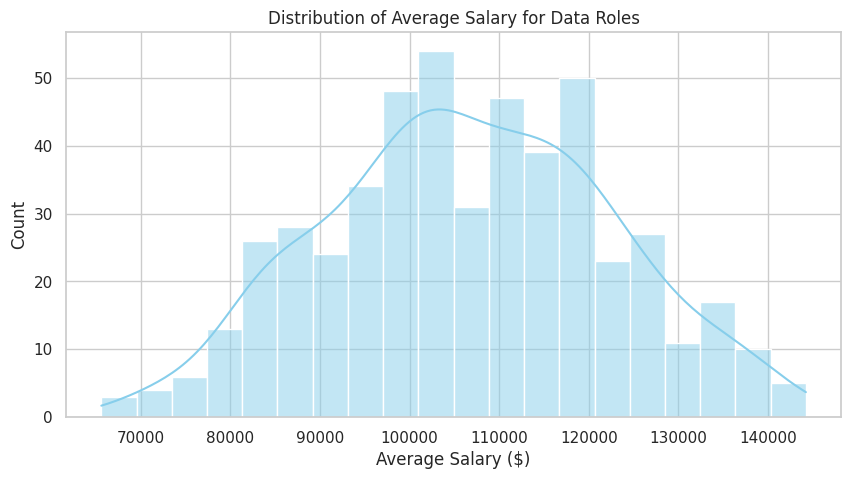

In [ ]:
# 1. Salary Distribution
plt.figure(figsize=(10, 5))
sns.histplot(df['Average_Salary'], kde=True, color='skyblue', bins=20)
plt.title('Distribution of Average Salary for Data Roles')
plt.xlabel('Average Salary ($)')
plt.ylabel('Count')
plt.show()

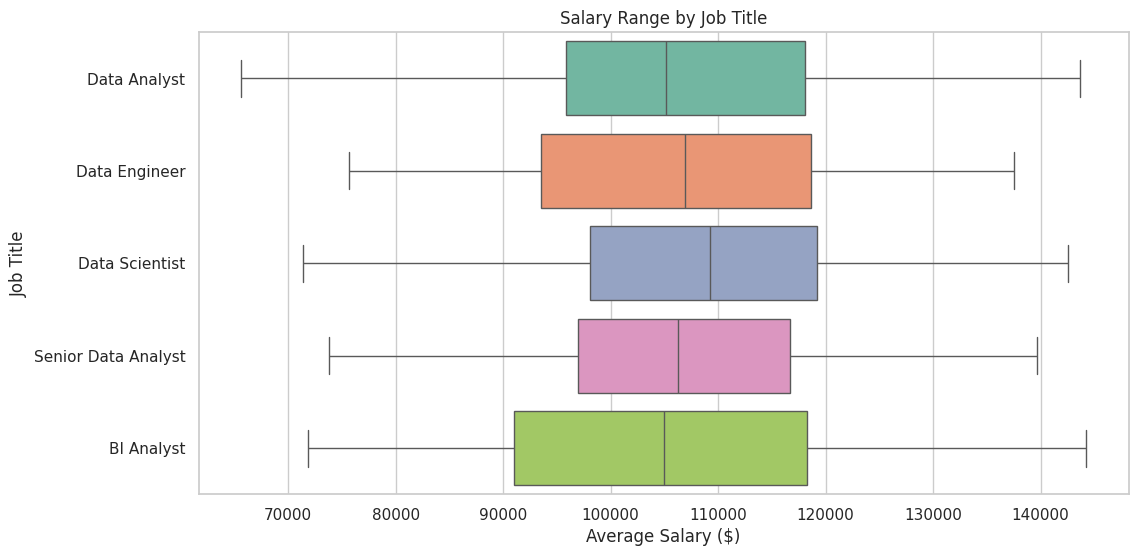

In [ ]:
# 2. Salary Range by Job Title
plt.figure(figsize=(12, 6))
sns.boxplot(data=df, x='Average_Salary', y='Job_Title', hue='Job_Title', palette='Set2', legend=False)
plt.title('Salary Range by Job Title')
plt.xlabel('Average Salary ($)')
plt.ylabel('Job Title')
plt.show()

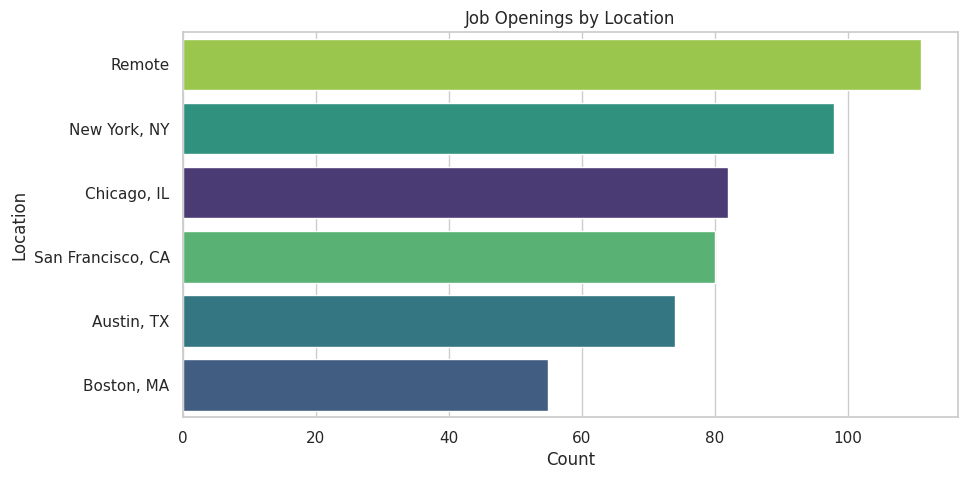

In [ ]:
# 3. Job Distribution by Location
plt.figure(figsize=(10, 5))
sns.countplot(data=df, y='Location', order=df['Location'].value_counts().index, hue='Location', palette='viridis', legend=False)
plt.title('Job Openings by Location')
plt.xlabel('Count')
plt.ylabel('Location')
plt.show()

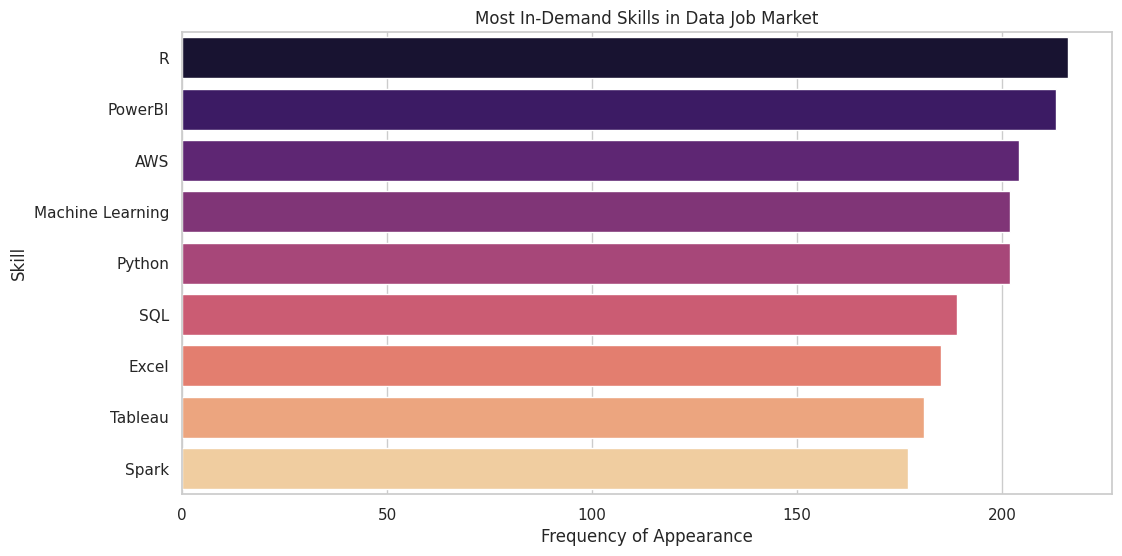

In [ ]:
# 4. Most Demanded Skills
all_skills = []
for desc in df['Job_Description']:
    all_skills.extend([skill.strip() for skill in desc.split(',')])

skills_count = Counter(all_skills)
skills_df = pd.DataFrame(skills_count.items(), columns=['Skill', 'Frequency']).sort_values(by='Frequency', ascending=False)

plt.figure(figsize=(12, 6))
sns.barplot(data=skills_df, x='Frequency', y='Skill', hue='Skill', palette='magma', legend=False)
plt.title('Most In-Demand Skills in Data Job Market')
plt.xlabel('Frequency of Appearance')
plt.ylabel('Skill')
plt.show()

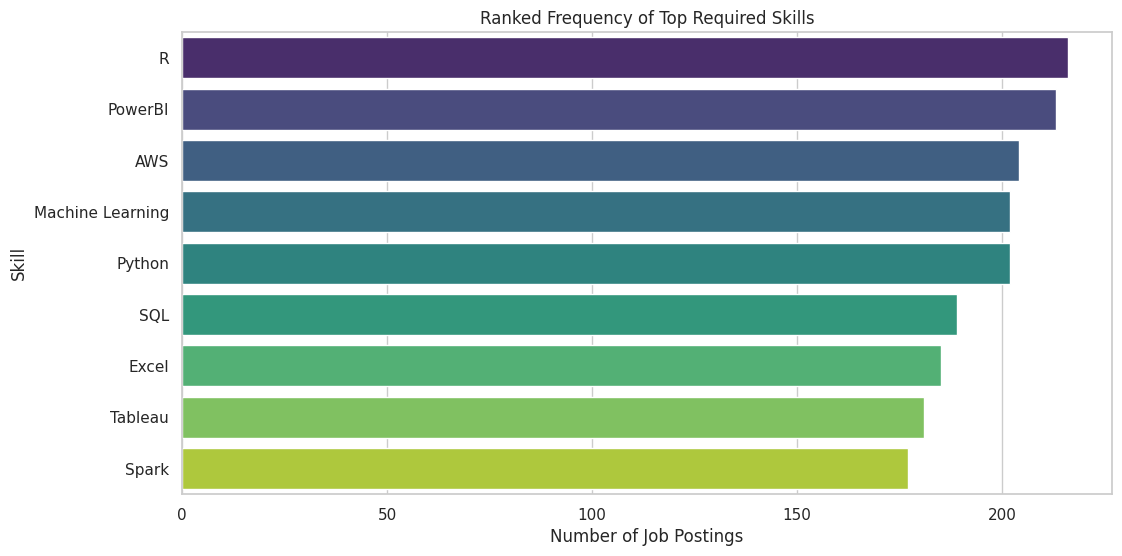

In [ ]:
# Visualize top skills frequency
plt.figure(figsize=(12, 6))
sns.barplot(data=skills_df, x='Frequency', y='Skill', hue='Skill', palette='viridis', legend=False)
plt.title('Ranked Frequency of Top Required Skills')
plt.xlabel('Number of Job Postings')
plt.ylabel('Skill')
plt.show()

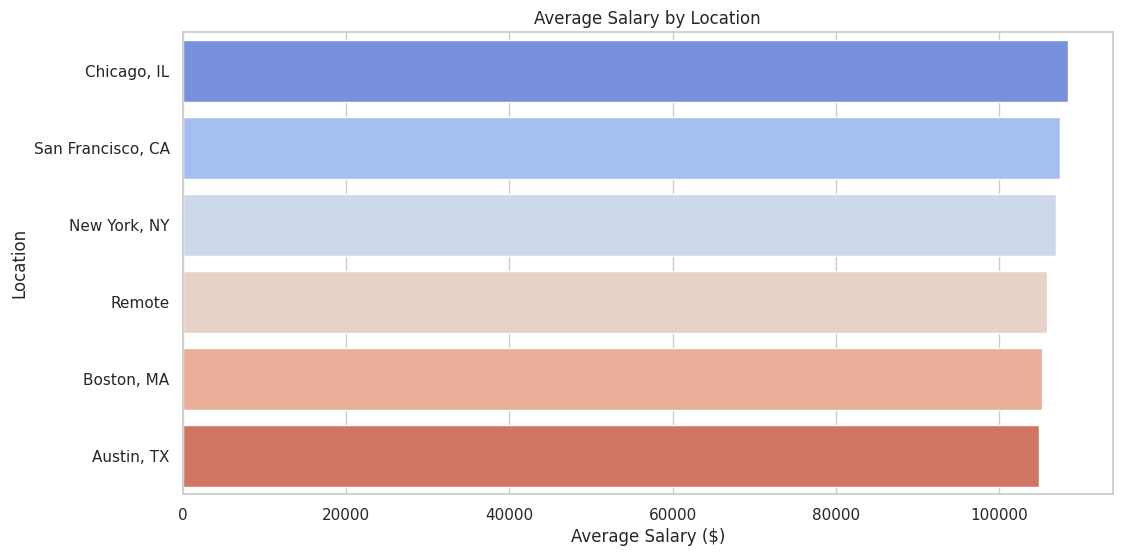

In [ ]:
# Calculate mean average salary by location
salary_by_location = df.groupby('Location')['Average_Salary'].mean().reset_index().sort_values(by='Average_Salary', ascending=False)

# Create the bar chart
plt.figure(figsize=(12, 6))
sns.barplot(data=salary_by_location, x='Average_Salary', y='Location', hue='Location', palette='coolwarm', legend=False)
plt.title('Average Salary by Location')
plt.xlabel('Average Salary ($)')
plt.ylabel('Location')
plt.show()

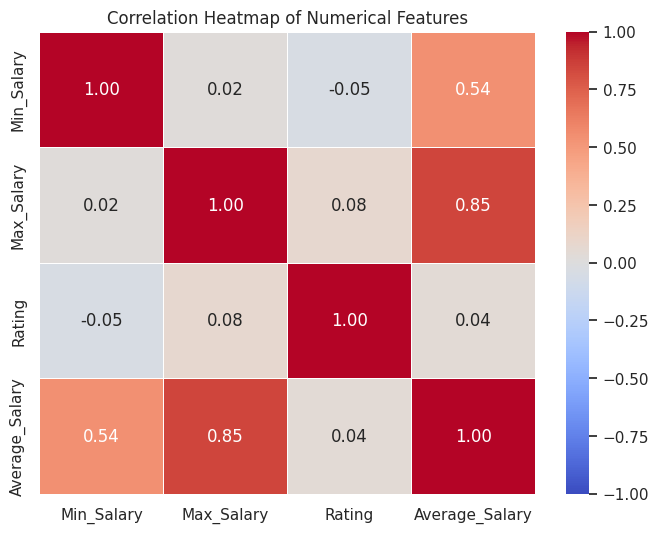

In [ ]:
# Calculate the correlation matrix for numerical columns
numerical_cols = ['Min_Salary', 'Max_Salary', 'Rating', 'Average_Salary']
corr_matrix = df[numerical_cols].corr()

# Generate the correlation heatmap
plt.figure(figsize=(8, 6))
sns.heatmap(corr_matrix, annot=True, cmap='coolwarm', fmt='.2f', linewidths=0.5, vmin=-1, vmax=1)
plt.title('Correlation Heatmap of Numerical Features')
plt.show()

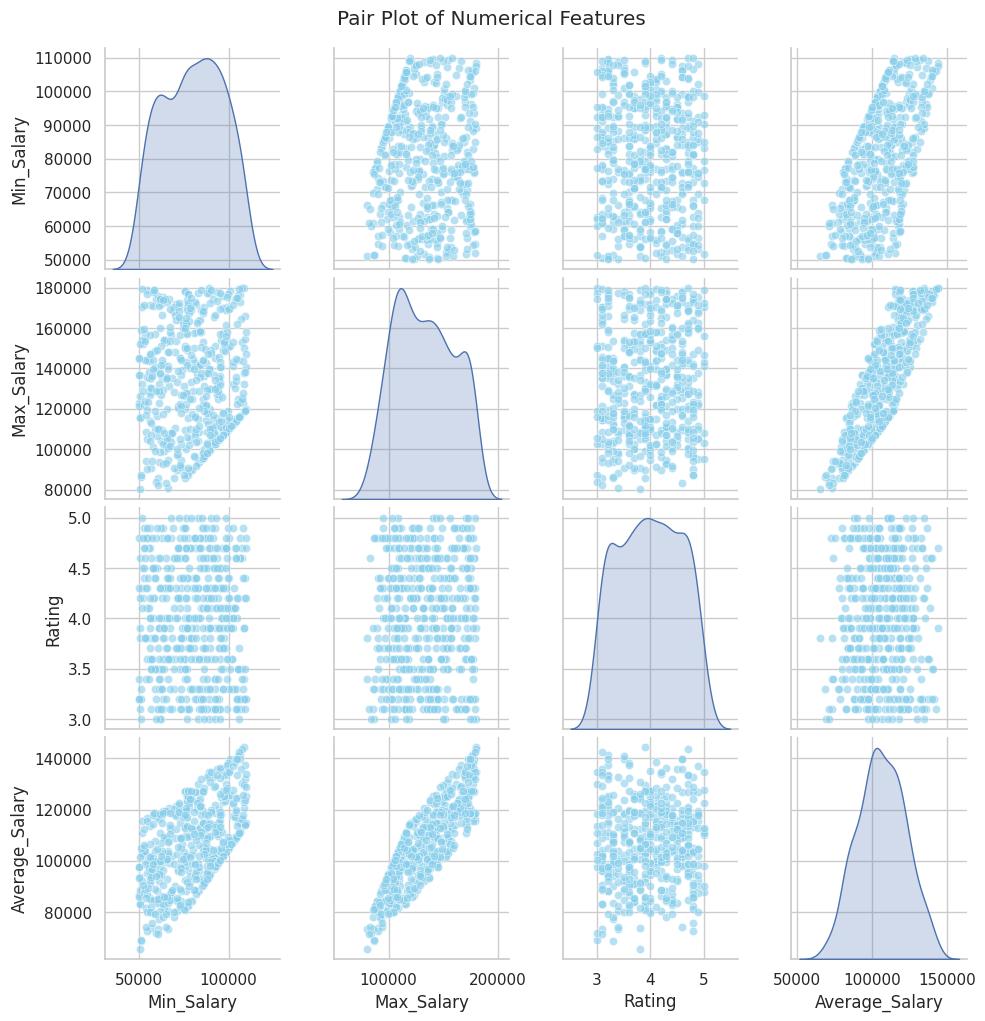

In [ ]:
# Generate a pair plot for numerical variables
sns.pairplot(df[numerical_cols], diag_kind='kde', plot_kws={'alpha': 0.6, 'color': 'skyblue'})
plt.suptitle('Pair Plot of Numerical Features', y=1.02)
plt.show()

,Job_Title,Rating
1,Data Analyst,4.029469
3,Data Scientist,4.001316
4,Senior Data Analyst,3.950000
0,BI Analyst,3.932895
2,Data Engineer,3.925455


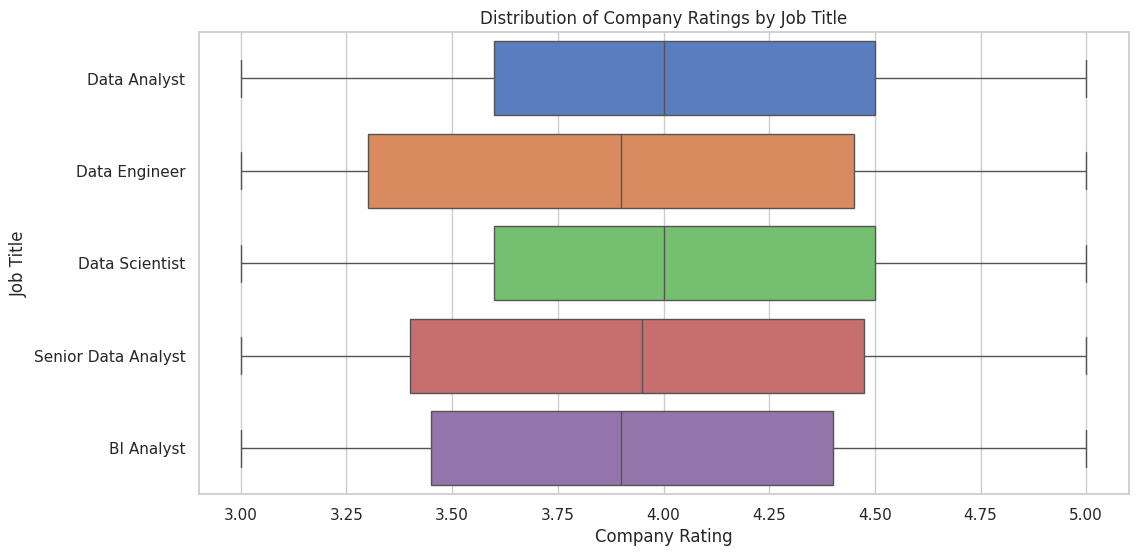

In [ ]:
# Calculate mean rating by Job Title
rating_by_job = df.groupby('Job_Title')['Rating'].mean().reset_index().sort_values(by='Rating', ascending=False)
display(rating_by_job)

# Visualize Rating distribution by Job Title
plt.figure(figsize=(12, 6))
sns.boxplot(data=df, x='Rating', y='Job_Title', hue='Job_Title', palette='muted', legend=False)
plt.title('Distribution of Company Ratings by Job Title')
plt.xlabel('Company Rating')
plt.ylabel('Job Title')
plt.show()

In [ ]:
# Filter for Data Scientist positions
ds_jobs = df[df['Job_Title'] == 'Data Scientist']

# Extract and count skills
ds_skills = []
for desc in ds_jobs['Job_Description']:
    ds_skills.extend([skill.strip() for skill in desc.split(',')])

ds_skills_count = Counter(ds_skills)
top_3_ds_skills = ds_skills_count.most_common(3)

# Display the top 3 skills
print("--- Top 3 Skills for Data Scientist Positions ---")
for i, (skill, count) in enumerate(top_3_ds_skills, 1):
    print(f"{i}. {skill}: {count} occurrences")

--- Top 3 Skills for Data Scientist Positions ---
1. Machine Learning: 34 occurrences
2. R: 33 occurrences
3. SQL: 32 occurrences


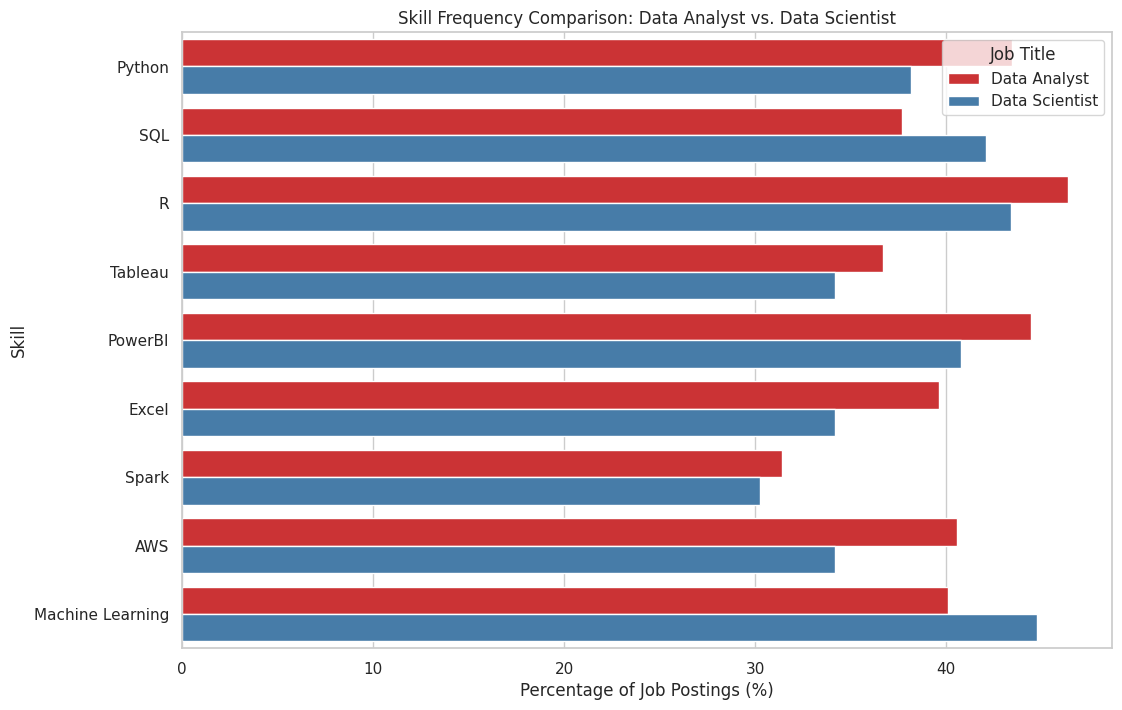

In [ ]:
from collections import Counter
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# 1. Filter and extract skills for Data Analyst
da_jobs = df[df['Job_Title'] == 'Data Analyst']
da_skills = []
for desc in da_jobs['Job_Description']:
    da_skills.extend([skill.strip() for skill in desc.split(',')])

da_count = Counter(da_skills)
da_total = len(da_jobs)

# 2. Filter and extract skills for Data Scientist
ds_jobs = df[df['Job_Title'] == 'Data Scientist']
ds_skills = []
for desc in ds_jobs['Job_Description']:
    ds_skills.extend([skill.strip() for skill in desc.split(',')])

ds_count = Counter(ds_skills)
ds_total = len(ds_jobs)

# 3. Create a combined DataFrame for comparison
comparison_data = []
for skill in skills_pool:
    da_freq = da_count.get(skill, 0)
    ds_freq = ds_count.get(skill, 0)

    # Percentage representation
    da_pct = (da_freq / da_total) * 100 if da_total > 0 else 0
    ds_pct = (ds_freq / ds_total) * 100 if ds_total > 0 else 0

    comparison_data.append({'Skill': skill, 'Job_Title': 'Data Analyst', 'Percentage': da_pct, 'Count': da_freq})
    comparison_data.append({'Skill': skill, 'Job_Title': 'Data Scientist', 'Percentage': ds_pct, 'Count': ds_freq})

comp_df = pd.DataFrame(comparison_data)

# 4. Plot the comparison side-by-side using percentages
plt.figure(figsize=(12, 8))
sns.barplot(data=comp_df, x='Percentage', y='Skill', hue='Job_Title', palette='Set1')
plt.title('Skill Frequency Comparison: Data Analyst vs. Data Scientist')
plt.xlabel('Percentage of Job Postings (%)')
plt.ylabel('Skill')
plt.legend(title='Job Title')
plt.show()

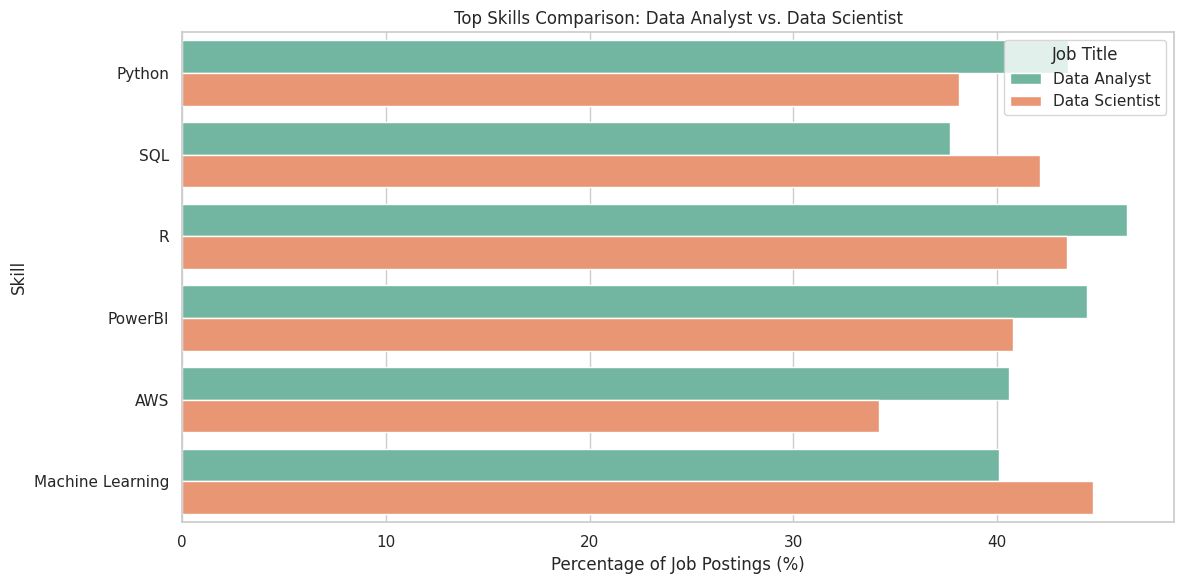

In [ ]:
# 1. Identify the top 5 skills for Data Analyst and Data Scientist
top_da_skills = [skill for skill, count in da_count.most_common(5)]
top_ds_skills = [skill for skill, count in ds_count.most_common(5)]

# Combine to get a unique set of top skills across both roles (or we can focus on the top 5 overall pool)
top_combined_skills = list(set(top_da_skills + top_ds_skills))

# Filter the comparison DataFrame for these top skills
filtered_comp_df = comp_df[comp_df['Skill'].isin(top_combined_skills)]

# 2. Plot the comparison
plt.figure(figsize=(12, 6))
sns.barplot(data=filtered_comp_df, x='Percentage', y='Skill', hue='Job_Title', palette='Set2')
plt.title('Top Skills Comparison: Data Analyst vs. Data Scientist')
plt.xlabel('Percentage of Job Postings (%)')
plt.ylabel('Skill')
plt.legend(title='Job Title')
plt.tight_layout()
plt.show()

In [ ]:
from scipy import stats

# Extract salaries for both roles
da_salaries = df[df['Job_Title'] == 'Data Analyst']['Average_Salary']
ds_salaries = df[df['Job_Title'] == 'Data Scientist']['Average_Salary']

# Perform an independent two-sample t-test (Welch's t-test)
t_stat, p_val = stats.ttest_ind(da_salaries, ds_salaries, equal_var=False)

print(f"Data Analyst Mean Salary: ${da_salaries.mean():,.2f} (n={len(da_salaries)})")
print(f"Data Scientist Mean Salary: ${ds_salaries.mean():,.2f} (n={len(ds_salaries)})")
print(f"T-statistic: {t_stat:.4f}")
print(f"P-value: {p_val:.4f}")

# Interpret the result
alpha = 0.05
if p_val < alpha:
    print("\nResult: The difference in average salaries is statistically significant (reject the null hypothesis).")
else:
    print("\nResult: The difference in average salaries is NOT statistically significant (fail to reject the null hypothesis).")

Data Analyst Mean Salary: $106,559.09 (n=207)
Data Scientist Mean Salary: $108,649.67 (n=76)
T-statistic: -0.9949
P-value: 0.3215

Result: The difference in average salaries is NOT statistically significant (fail to reject the null hypothesis).


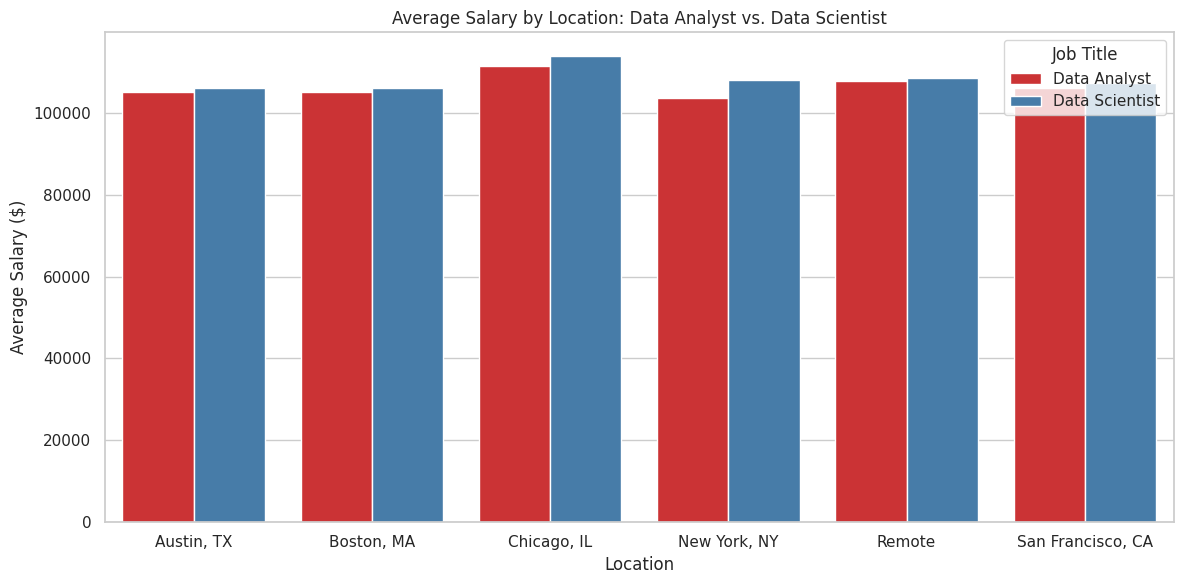

In [ ]:
# 1. Group by Location and Job Title to calculate mean salary and sample sizes
location_salary = df[df['Job_Title'].isin(['Data Analyst', 'Data Scientist'])].groupby(['Location', 'Job_Title'])['Average_Salary'].agg(['mean', 'count']).reset_index()

# 2. Plot the comparative average salary by location
plt.figure(figsize=(12, 6))
sns.barplot(data=location_salary, x='Location', y='mean', hue='Job_Title', palette='Set1')
plt.title('Average Salary by Location: Data Analyst vs. Data Scientist')
plt.xlabel('Location')
plt.ylabel('Average Salary ($)')
plt.legend(title='Job Title')
plt.tight_layout()
plt.show()

In [ ]:
# 3. Perform statistical testing (t-test) for each location separately
print("--- T-Test Analysis by Location ---")
unique_locations = df['Location'].unique()

for loc in unique_locations:
    da_loc_salaries = df[(df['Location'] == loc) & (df['Job_Title'] == 'Data Analyst')]['Average_Salary']
    ds_loc_salaries = df[(df['Location'] == loc) & (df['Job_Title'] == 'Data Scientist')]['Average_Salary']

    print(f"\nLocation: {loc}")
    print(f"  Data Analyst Mean: ${da_loc_salaries.mean():,.2f} (n={len(da_loc_salaries)})")
    print(f"  Data Scientist Mean: ${ds_loc_salaries.mean():,.2f} (n={len(ds_loc_salaries)})")

    if len(da_loc_salaries) > 1 and len(ds_loc_salaries) > 1:
        t_stat, p_val = stats.ttest_ind(da_loc_salaries, ds_loc_salaries, equal_var=False)
        print(f"  T-statistic: {t_stat:.4f}, P-value: {p_val:.4f}")
        if p_val < 0.05:
            print("  Result: Statistically SIGNIFICANT difference.")
        else:
            print("  Result: No statistically significant difference.")
    else:
        print("  Result: Insufficient sample size to perform a t-test.")

--- T-Test Analysis by Location ---

Location: Chicago, IL
  Data Analyst Mean: $111,418.42 (n=33)
  Data Scientist Mean: $113,959.00 (n=13)
  T-statistic: -0.5404, P-value: 0.5936
  Result: No statistically significant difference.

Location: Boston, MA
  Data Analyst Mean: $104,997.80 (n=25)
  Data Scientist Mean: $106,038.00 (n=4)
  T-statistic: -0.2043, P-value: 0.8412
  Result: No statistically significant difference.

Location: Austin, TX
  Data Analyst Mean: $104,971.43 (n=28)
  Data Scientist Mean: $106,042.05 (n=11)
  T-statistic: -0.1970, P-value: 0.8460
  Result: No statistically significant difference.

Location: New York, NY
  Data Analyst Mean: $103,524.44 (n=39)
  Data Scientist Mean: $107,972.42 (n=18)
  T-statistic: -0.7869, P-value: 0.4386
  Result: No statistically significant difference.

Location: San Francisco, CA
  Data Analyst Mean: $106,048.07 (n=34)
  Data Scientist Mean: $107,359.05 (n=10)
  T-statistic: -0.2907, P-value: 0.7741
  Result: No statistically sign

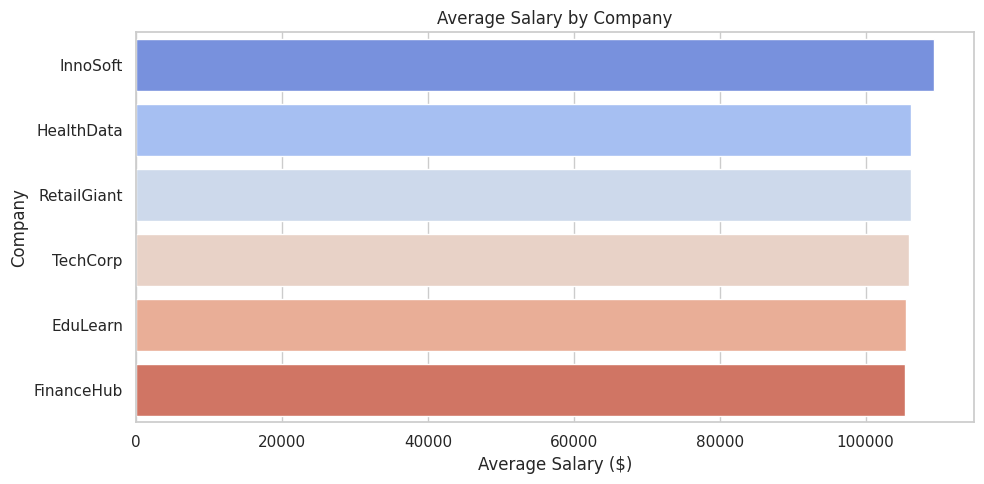

In [ ]:
# Calculate mean average salary by company
salary_by_company = df.groupby('Company')['Average_Salary'].mean().reset_index().sort_values(by='Average_Salary', ascending=False)

# Create a bar chart for the companies (we show all unique companies since there are only 6 simulated)
plt.figure(figsize=(10, 5))
sns.barplot(data=salary_by_company, x='Average_Salary', y='Company', hue='Company', palette='coolwarm', legend=False)
plt.title('Average Salary by Company')
plt.xlabel('Average Salary ($)')
plt.ylabel('Company')
plt.tight_layout()
plt.show()

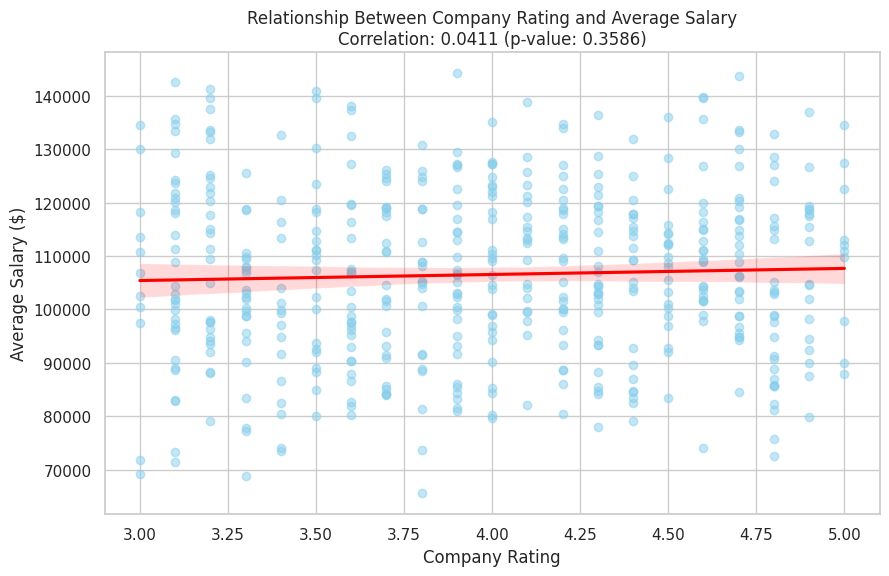

Pearson Correlation Coefficient: 0.0411
P-value: 0.3586


In [ ]:
import scipy.stats as stats

# Calculate correlation coefficient
correlation, p_value = stats.pearsonr(df['Rating'], df['Average_Salary'])

# Create a scatter plot with a regression line
plt.figure(figsize=(10, 6))
sns.regplot(data=df, x='Rating', y='Average_Salary', scatter_kws={'alpha':0.5, 'color': 'skyblue'}, line_kws={'color': 'red'})
plt.title(f'Relationship Between Company Rating and Average Salary\nCorrelation: {correlation:.4f} (p-value: {p_value:.4f})')
plt.xlabel('Company Rating')
plt.ylabel('Average Salary ($)')
plt.show()

print(f"Pearson Correlation Coefficient: {correlation:.4f}")
print(f"P-value: {p_value:.4f}")

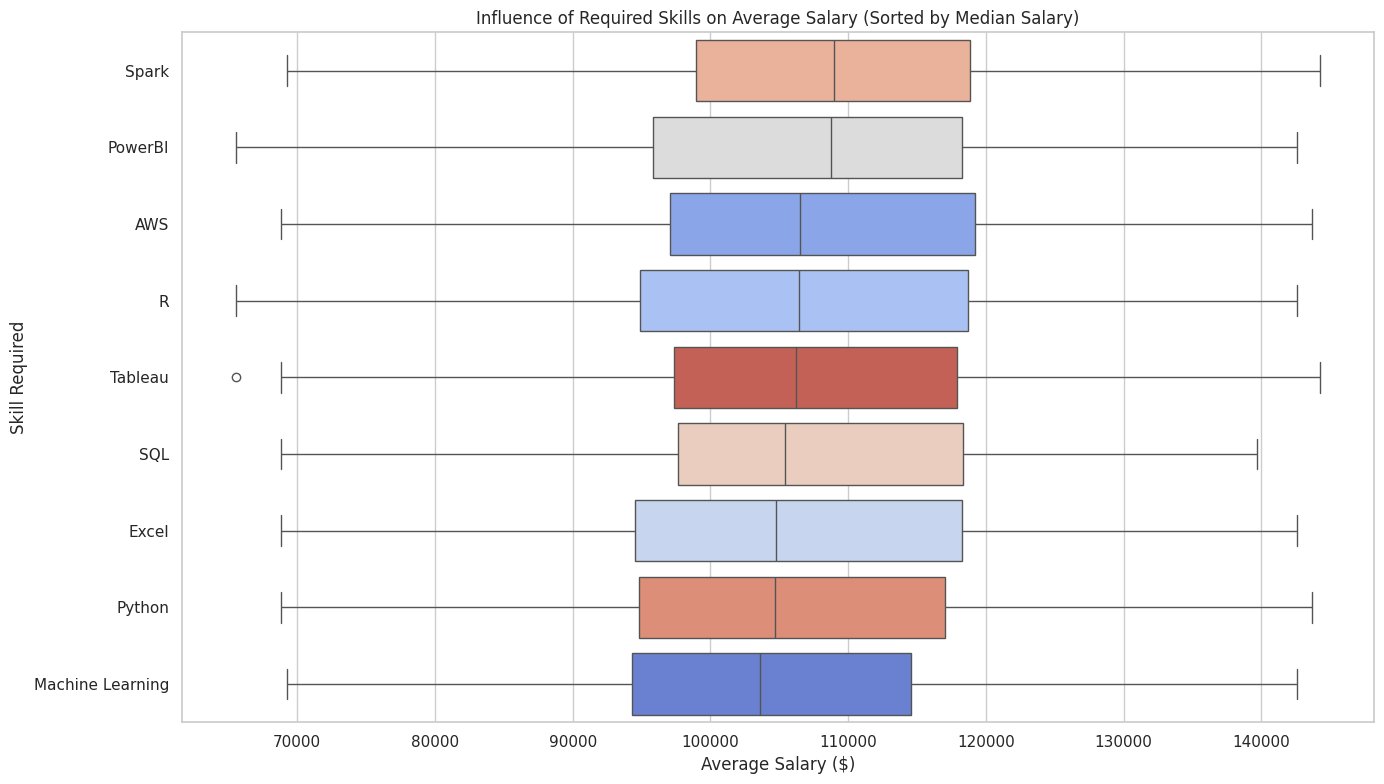

In [ ]:
# 1. Prepare data by expanding (exploding) the skills listed in Job_Description
# Create a copy with split lists
skills_df_exploded = df.copy()
skills_df_exploded['Skill'] = skills_df_exploded['Job_Description'].apply(lambda x: [s.strip() for s in x.split(',')])

# Explode the lists so each skill gets its own row
skills_df_exploded = skills_df_exploded.explode('Skill')

# Sort skills by their median average salary to make the visualization easier to read
skill_order = skills_df_exploded.groupby('Skill')['Average_Salary'].median().sort_values(ascending=False).index

# 2. Generate the boxplot
plt.figure(figsize=(14, 8))
sns.boxplot(
    data=skills_df_exploded,
    x='Average_Salary',
    y='Skill',
    order=skill_order,
    hue='Skill',
    palette='coolwarm',
    legend=False
)

plt.title('Influence of Required Skills on Average Salary (Sorted by Median Salary)')
plt.xlabel('Average Salary ($)')
plt.ylabel('Skill Required')
plt.tight_layout()
plt.show()

,Skill_Combination,Frequency,Percentage (%)
0,"Spark, Tableau",8,1.6
1,"AWS, Spark",7,1.4
2,"Machine Learning, PowerBI",6,1.2
3,"R, Spark",6,1.2
4,"PowerBI, R",6,1.2
5,"SQL, Tableau",5,1.0
6,"R, SQL",5,1.0
7,"AWS, Tableau",5,1.0
8,"Python, SQL",5,1.0
9,"Machine Learning, R",4,0.8


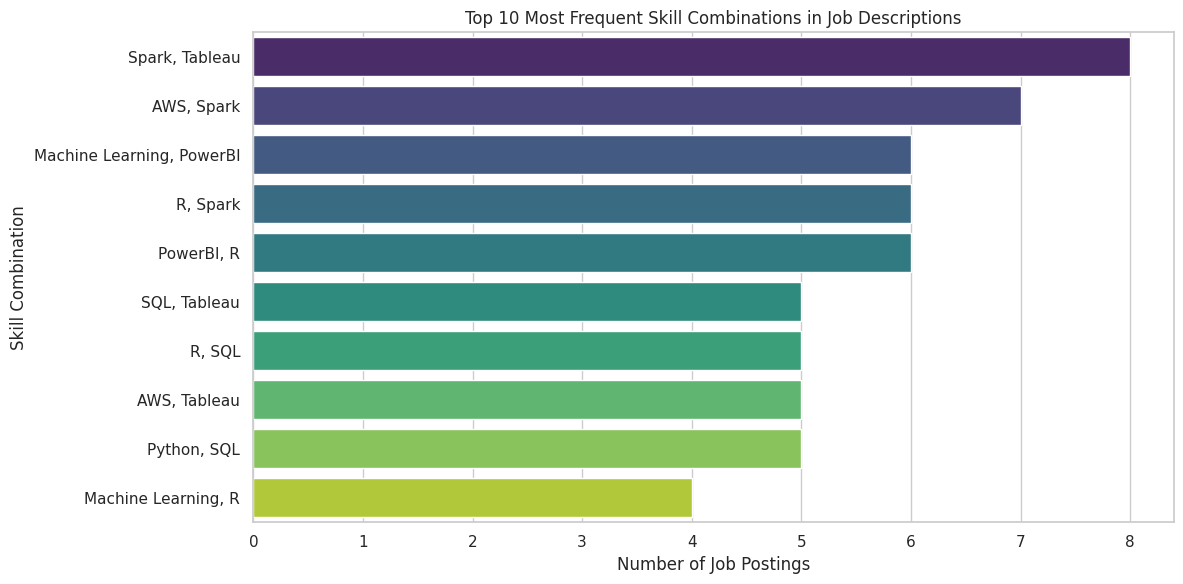

In [ ]:
from collections import Counter

# Extract and normalize skill combinations
combinations = []
for desc in df['Job_Description']:
    # Split, strip whitespace, and sort to ensure order-independent combinations
    skills = sorted([skill.strip() for skill in desc.split(',')])
    # Convert to tuple so it can be hashed and counted
    combinations.append(tuple(skills))

# Count the frequencies of each combination
combo_counts = Counter(combinations)

# Create a DataFrame for the top 10 most common combinations
top_combos = combo_counts.most_common(10)
combo_data = []
for combo, count in top_combos:
    combo_data.append({
        'Skill_Combination': ", ".join(combo),
        'Frequency': count,
        'Percentage (%)': (count / len(df)) * 100
    })

combo_df = pd.DataFrame(combo_data)
display(combo_df)

# Plot the top combinations
plt.figure(figsize=(12, 6))
sns.barplot(data=combo_df, x='Frequency', y='Skill_Combination', hue='Skill_Combination', palette='viridis', legend=False)
plt.title('Top 10 Most Frequent Skill Combinations in Job Descriptions')
plt.xlabel('Number of Job Postings')
plt.ylabel('Skill Combination')
plt.tight_layout()
plt.show()